# EDA 2 — DICOM metadata

This notebook looks at the technical properties of the scans: number of slices, slice thickness,
pixel size, scanner, and which patient each series belongs to.

The table `data/interim/dicom_meta.csv` was made on Kaggle by `kaggle/extract_dicom_meta.py`,
which reads only the DICOM headers of all 4,348 training series (about 51 minutes).
It has one row per series.

Questions:
1. Does any patient have more than one series (leakage risk for CV)?
2. How different are the scans in size and resolution, per modality?
3. Which values are missing, and why?
4. Do the DICOM headers agree with `train.csv`?

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.utils import ID_COL, TARGET_COL

train = pd.read_csv(ROOT / "data" / "raw" / "train.csv")
meta = pd.read_csv(ROOT / "data" / "interim" / "dicom_meta.csv")

# Columns that also exist in train.csv get a "Dicom" prefix, so we can compare them
meta = meta.rename(columns={"Modality": "DicomModality", "PatientAge": "DicomAge", "PatientSex": "DicomSex"})
df = train[[ID_COL, "Modality", "PatientAge", "PatientSex", TARGET_COL]].merge(meta, on=ID_COL, how="left")

MODALITIES = ["CTA", "MRA", "MRI T2", "MRI T1post"]
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "axes.axisbelow": True,
    "axes.edgecolor": GRAY, "axes.labelcolor": GRAY, "xtick.color": GRAY, "ytick.color": GRAY,
})


def box_by_modality(ax, col, title, log=False):
    """Horizontal box plot of one column, one box per modality."""
    data = [df.loc[df["Modality"] == m, col].dropna() for m in MODALITIES]
    ax.boxplot(data, orientation="horizontal", tick_labels=MODALITIES, widths=0.5, patch_artist=True,
               boxprops=dict(facecolor="#2a78d633", edgecolor=BLUE),
               medianprops=dict(color=ORANGE, lw=2),
               whiskerprops=dict(color=GRAY), capprops=dict(color=GRAY),
               flierprops=dict(marker="o", ms=3, mfc=GRAY, mec="none", alpha=0.4))
    if not ax.yaxis_inverted():  # shared y axes are inverted only once
        ax.invert_yaxis()
    if log:
        ax.set_xscale("log")
    ax.set_title(title)


def summary_by_modality(col):
    return df.groupby("Modality")[col].describe(percentiles=[0.05, 0.5, 0.95]).loc[MODALITIES].round(2)

## 1. Merge check

In [2]:
print("Rows in meta:", len(meta), "| rows in train.csv:", len(train))
print("Series in train.csv without metadata:", df["n_files"].isna().sum())
print("Read errors:", meta["error"].notna().sum() if "error" in meta else 0)
print("Columns:", list(meta.columns))

Rows in meta: 4348 | rows in train.csv: 4348
Series in train.csv without metadata: 0
Read errors: 0
Columns: ['SeriesInstanceUID', 'n_files', 'PatientID', 'DicomModality', 'Manufacturer', 'ManufacturerModelName', 'MagneticFieldStrength', 'DicomAge', 'DicomSex', 'Rows', 'Columns', 'BitsStored', 'PhotometricInterpretation', 'RescaleSlope', 'RescaleIntercept', 'SliceThickness', 'SpacingBetweenSlices', 'WindowCenter', 'WindowWidth', 'is_multiframe', 'n_slices', 'PixelSpacingRow', 'PixelSpacingCol', 'slice_spacing', 'z_extent_mm']


## 2. Patients and leakage

`train.csv` has no patient ID, but the DICOM header does. If one patient had several series and they ended up
in different CV folds, the model could recognise the patient instead of the aneurysm, and the CV score would be too optimistic.

In [3]:
per_patient = df.groupby("PatientID").size()
print("Series:", len(df), "| unique PatientID:", df["PatientID"].nunique())
print("Patients with more than one series:", (per_patient > 1).sum())

Series: 4348 | unique PatientID: 4348
Patients with more than one series: 0


Every series has its own `PatientID`. The IDs are anonymised, so we cannot rule out that one person got two different IDs,
but based on the data we have there is no patient overlap. **The CV split does not need patient grouping.**

## 3. Number of slices

How many 2D slices one 3D scan has.

             count    mean     std   min     5%    50%     95%     max
Modality                                                              
CTA         1808.0  402.21  254.41  22.0   60.0  334.0  891.65  1441.0
MRA         1252.0  175.69   52.67  22.0  106.0  164.0  266.00   514.0
MRI T2       983.0   35.06   22.40  15.0   20.0   30.0   59.00   312.0
MRI T1post   305.0  154.74   94.33  15.0   25.0  166.0  302.40   340.0


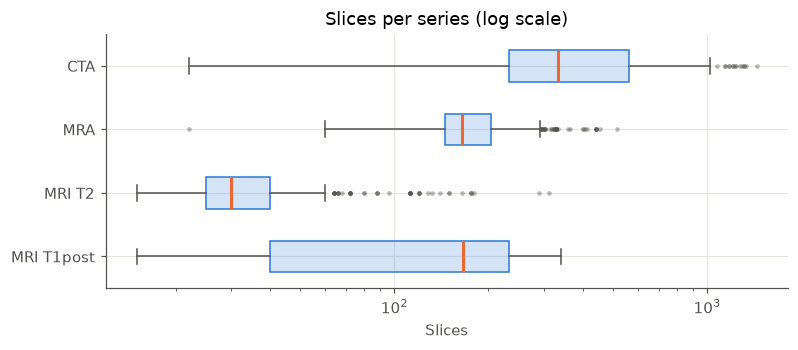

In [4]:
print(summary_by_modality("n_slices"))
fig, ax = plt.subplots(figsize=(8, 3))
box_by_modality(ax, "n_slices", "Slices per series (log scale)", log=True)
ax.set_xlabel("Slices")
plt.show()

## 4. Slice thickness and spacing

- `SliceThickness`: how thick each slice is (mm), from the header.
- `slice_spacing`: the real distance between neighbouring slices (mm), computed from the slice positions.

They are not always the same: slices can overlap (spacing < thickness) or have gaps (spacing > thickness).
For resampling a volume, the spacing is what matters.

SliceThickness
             count  mean   std   min   5%  50%  95%   max
Modality                                                 
CTA         1808.0  1.21  1.22  0.47  0.5  0.8  5.0  10.2
MRA         1252.0  0.83  0.41  0.30  0.5  0.6  1.6   5.0
MRI T2       983.0  4.29  1.06  0.50  2.0  5.0  5.0   6.0
MRI T1post   305.0  2.09  1.53  0.80  0.9  1.2  5.0   5.0

slice_spacing
             count  mean   std  min   5%   50%  95%   max
Modality                                                 
CTA         1808.0  1.05  1.23  0.0  0.3  0.62  5.0  10.0
MRA         1252.0  0.61  0.18  0.0  0.5  0.55  0.8   5.0
MRI T2       983.0  4.81  1.41  0.4  2.2  5.00  7.0   7.0
MRI T1post   305.0  2.16  1.98  0.5  0.6  1.00  6.0   7.0


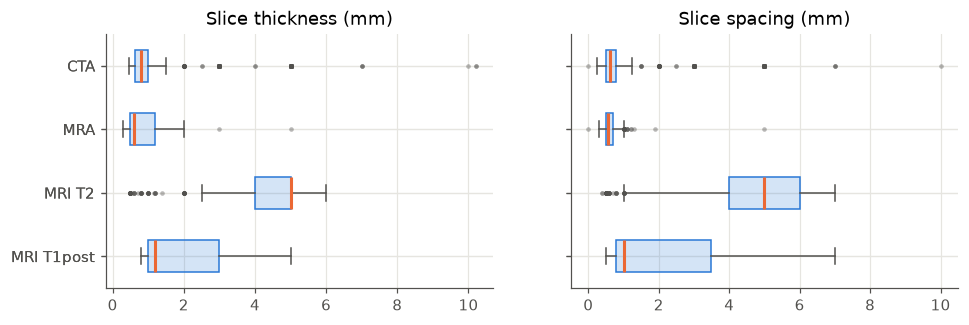

Share of series where thickness and spacing differ by more than 0.1 mm:
Modality
CTA           47%
MRA           33%
MRI T2        51%
MRI T1post    46%


In [5]:
print("SliceThickness"); print(summary_by_modality("SliceThickness"))
print("\nslice_spacing"); print(summary_by_modality("slice_spacing"))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
box_by_modality(ax1, "SliceThickness", "Slice thickness (mm)")
box_by_modality(ax2, "slice_spacing", "Slice spacing (mm)")
plt.show()

differs = (df["SliceThickness"] - df["slice_spacing"]).abs() > 0.1
print("Share of series where thickness and spacing differ by more than 0.1 mm:")
print(differs.groupby(df["Modality"]).mean().loc[MODALITIES].map("{:.0%}".format).to_string())

## 5. Pixel size and image size

`PixelSpacingRow` is the size of one pixel in mm inside a slice. `Rows × Columns` is the image size in pixels.

             count  mean   std   min    5%   50%  95%   max
Modality                                                   
CTA         1808.0  0.47  0.07  0.22  0.39  0.47  0.6  0.92
MRA         1252.0  0.41  0.11  0.20  0.26  0.41  0.6  1.02
MRI T2       983.0  0.52  0.15  0.21  0.31  0.50  0.8  1.00
MRI T1post   305.0  0.65  0.25  0.21  0.34  0.50  1.0  1.17

Pixel spacing is square (row == col): 99.7%

164 different image sizes. Most common:
512 x 512      2900
768 x 696       119
528 x 528       110
256 x 256        99
480 x 480        76
1024 x 1024      62
320 x 320        61
320 x 280        61
384 x 384        44
384 x 300        39


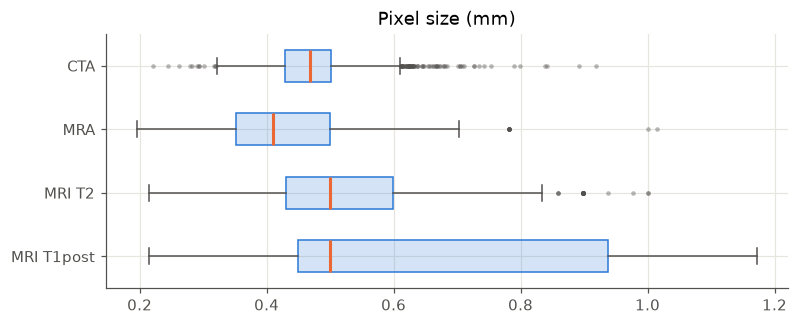

In [6]:
print(summary_by_modality("PixelSpacingRow"))
print("\nPixel spacing is square (row == col):", f"{(df['PixelSpacingRow'] == df['PixelSpacingCol']).mean():.1%}")

sizes = (df["Rows"].astype(int).astype(str) + " x " + df["Columns"].astype(int).astype(str)).value_counts()
print(f"\n{len(sizes)} different image sizes. Most common:")
print(sizes.head(10).to_string())

fig, ax = plt.subplots(figsize=(8, 3))
box_by_modality(ax, "PixelSpacingRow", "Pixel size (mm)")
plt.show()

## 6. Physical length of the scan

`z_extent_mm` is the distance from the first to the last slice: how much of the body the scan covers.
A head is roughly 150–200 mm tall, so longer scans also include the neck or chest.

             count    mean    std    min     5%     50%     95%     max
Modality                                                               
CTA         1808.0  248.70  99.29  58.63  113.9  206.31  391.00  570.00
MRA         1252.0  102.27  26.29  35.40   74.9   97.80  154.04  284.90
MRI T2       983.0  140.17  25.16  27.50  105.3  145.00  168.00  220.00
MRI T1post   305.0  173.07  34.56  46.20  135.0  169.50  241.20  268.92


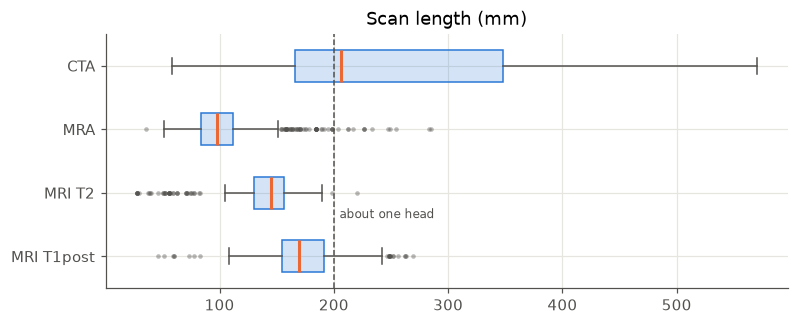

Series longer than 250 mm:
Modality
CTA           808
MRA             3
MRI T2          0
MRI T1post      7


In [7]:
print(summary_by_modality("z_extent_mm"))
fig, ax = plt.subplots(figsize=(8, 3))
box_by_modality(ax, "z_extent_mm", "Scan length (mm)")
ax.axvline(200, color=GRAY, ls="--", lw=1)
ax.text(205, 3.4, "about one head", color=GRAY, fontsize=8)
plt.show()
print("Series longer than 250 mm:")
print((df["z_extent_mm"] > 250).groupby(df["Modality"]).sum().loc[MODALITIES].to_string())

## 7. Single-file (multi-frame) series

Most series store one slice per DICOM file. Some store the whole volume in one multi-frame file.
The loader in `src/data.py` must handle both.

In [8]:
mf = pd.crosstab(df["Modality"], df["is_multiframe"]).loc[MODALITIES]
mf.columns = ["one file per slice", "one multi-frame file"]
print(mf.to_string())
print("\nFile count of multi-frame series:", df.loc[df["is_multiframe"], "n_files"].value_counts().to_dict())

            one file per slice  one multi-frame file
Modality                                            
CTA                       1808                     0
MRA                       1095                   157
MRI T2                     818                   165
MRI T1post                 305                     0



File count of multi-frame series: {1: 322}


## 8. Scanner manufacturer

The data comes from many hospitals with different scanners. Manufacturer names are written in several ways
(`SIEMENS`, `Siemens Healthineers`, ...), so we keep only the first word in upper case.

               series positive_rate
Vendor                             
SIEMENS          1761         42.1%
GE               1329         38.3%
PHILIPS           782         43.7%
TOSHIBA/CANON     472         57.4%
HITACHI             4          0.0%

Series per vendor and modality:
Modality       CTA  MRA  MRI T2  MRI T1post
Vendor                                     
SIEMENS        534  659     416         152
GE             612  298     295         124
PHILIPS        276  224     254          28
TOSHIBA/CANON  386   70      16           0
HITACHI          0    1       2           1

Positive rate (%) per vendor within each modality:
Modality        CTA   MRA  MRI T2  MRI T1post
Vendor                                       
SIEMENS        57.7  43.4    26.4        24.3
GE             43.8  47.0    23.1        26.6
PHILIPS        55.8  47.3    29.5        25.0
TOSHIBA/CANON  63.0  32.9    31.2         NaN
HITACHI         NaN   0.0     0.0         0.0


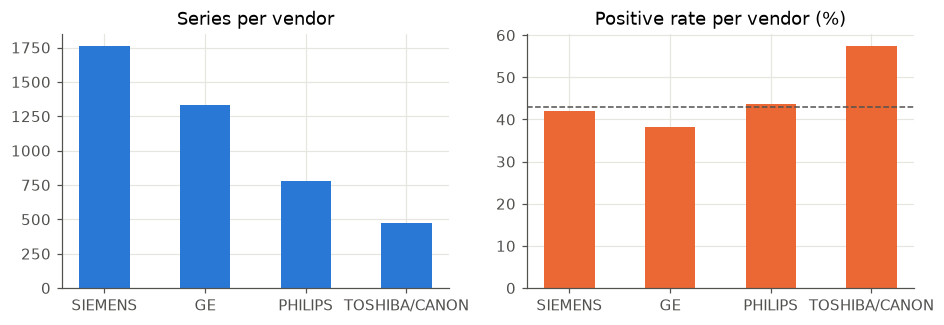

Magnetic field strength (MR only, tesla):
MagneticFieldStrength
1.50        1519
3.00        1006
1.16           4
15000.00       1
1.49           1


In [9]:
df["Vendor"] = (df["Manufacturer"].str.upper().str.replace(r"[^A-Z ]", " ", regex=True)
                .str.split().str[0].replace({"CANON": "TOSHIBA/CANON", "TOSHIBA": "TOSHIBA/CANON"}))
vendor = df.groupby("Vendor")[TARGET_COL].agg(series="size", positive_rate="mean").sort_values("series", ascending=False)
print(vendor.to_string(formatters={"positive_rate": "{:.1%}".format}))
print()
print("Series per vendor and modality:")
print(pd.crosstab(df["Vendor"], df["Modality"])[MODALITIES].loc[vendor.index].to_string())
print()
print("Positive rate (%) per vendor within each modality:")
print((df.pivot_table(index="Vendor", columns="Modality", values=TARGET_COL) * 100)
      .round(1)[MODALITIES].loc[vendor.index].to_string())

top = vendor[vendor["series"] >= 50]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3))
ax1.bar(top.index, top["series"], color=BLUE, width=0.5)
ax1.set_title("Series per vendor")
ax2.bar(top.index, top["positive_rate"] * 100, color=ORANGE, width=0.5)
ax2.axhline(df[TARGET_COL].mean() * 100, color=GRAY, ls="--", lw=1)
ax2.set_title("Positive rate per vendor (%)")
plt.show()

print("Magnetic field strength (MR only, tesla):")
print(df["MagneticFieldStrength"].round(2).value_counts().head(5).to_string())

## 9. Missing values

Which header fields are empty, and in which modality.

In [10]:
missing_cols = [c for c in meta.columns if meta[c].isna().any()]
missing = df.groupby("Modality")[missing_cols].apply(lambda g: g.isna().mean()).loc[MODALITIES].T
missing["total"] = df[missing_cols].isna().sum()
print((missing[MODALITIES] * 100).round(0).astype(int).astype(str).add("%")
      .assign(total=missing["total"]).to_string())
print("\nWindowCenter missing, by multi-frame:", df["WindowCenter"].isna().groupby(df["is_multiframe"]).mean().to_dict())

Modality                CTA  MRA MRI T2 MRI T1post  total
MagneticFieldStrength  100%   0%     0%         0%   1817
DicomAge                26%  29%    27%        19%   1163
DicomSex                19%  12%     9%        28%    662
RescaleSlope            38%  87%    91%        96%   2954
RescaleIntercept        38%  87%    91%        96%   2954
SpacingBetweenSlices    53%   1%     3%        34%   1099
WindowCenter             0%  13%    17%         0%    322
WindowWidth              0%  13%    17%         0%    322

WindowCenter missing, by multi-frame: {False: 0.0, True: 1.0}


## 10. Consistency with train.csv

In [11]:
print("Modality (train.csv vs DICOM):")
print(pd.crosstab(df["Modality"], df["DicomModality"]).loc[MODALITIES].to_string())

dicom_age = df["DicomAge"].str.extract(r"(\d+)")[0].astype(float)
age_diff = (dicom_age - df["PatientAge"]).dropna()
print(f"\nAge present in DICOM: {dicom_age.notna().sum()} series")
print("DICOM age - train.csv age:")
print(age_diff.describe().round(2).to_string())

print("\nSex in DICOM:", df["DicomSex"].value_counts(dropna=False).to_dict())
known = df["DicomSex"].isin(["F", "M"])
same = df.loc[known, "DicomSex"].map({"F": "Female", "M": "Male"}) == df.loc[known, "PatientSex"]
print(f"Sex matches train.csv (where DICOM says F or M): {same.mean():.1%}")

Modality (train.csv vs DICOM):
DicomModality    CT    MR
Modality                 
CTA            1808     0
MRA               0  1252
MRI T2            0   983
MRI T1post        0   305

Age present in DICOM: 3185 series
DICOM age - train.csv age:
count    3185.00
mean       -0.30
std         4.25
min       -54.00
25%        -1.00
50%         0.00
75%         1.00
max        47.00

Sex in DICOM: {'F': 2300, 'M': 1044, nan: 662, 'O': 342}
Sex matches train.csv (where DICOM says F or M): 96.6%


## 11. Unusual series

In [12]:
print("Slice spacing of 0 (several slices at the same position):")
print(df.loc[df["slice_spacing"] < 0.01, [ID_COL, "Modality", "n_slices", "SliceThickness", "z_extent_mm"]].to_string())
print("\nLongest scans:")
print(df.nlargest(5, "z_extent_mm")[["Modality", "n_slices", "slice_spacing", "z_extent_mm"]].to_string())
print("\nSeries with fewer than 20 slices:", (df["n_slices"] < 20).sum())

Slice spacing of 0 (several slices at the same position):
                                                     SeriesInstanceUID Modality  n_slices  SliceThickness  z_extent_mm
3302  1.2.826.0.1.3680043.8.498.72399220582146674554688600955035038848      MRA       144           1.800   127.800006
3868  1.2.826.0.1.3680043.8.498.87480891990277582946346790136781912242      CTA        96           0.625   118.500000

Longest scans:
     Modality  n_slices  slice_spacing  z_extent_mm
3955      CTA      1141            0.5        570.0
3236      CTA       545            1.0        544.0
2525      CTA      1023            0.5        511.0
670       CTA      1003            0.5        501.0
2088      CTA       498            1.0        497.0

Series with fewer than 20 slices: 48


## 12. Findings

**Patients**
- All 4,348 series were read without errors, and every series has its own `PatientID`.
  IDs are anonymised, so this is not a proof, but there is no visible patient overlap: the CV split does not need patient grouping.

**The scans are very different in size and resolution**
- Slices per series range from 15 to 1,441. Median: CTA 334, MRA 164, MRI T1post 166, MRI T2 30. 48 series have fewer than 20 slices.
- Median slice spacing: CTA 0.62 mm, MRA 0.55 mm, MRI T1post 1.0 mm, MRI T2 5.0 mm.
  MRI T2 are thick-slice scans: an aneurysm of a few millimetres may appear on only one or two slices.
- In about a third to half of the series, `SliceThickness` differs from the real slice spacing, so resampling should use the computed `slice_spacing`.
- Pixel size is 0.2–1.2 mm (median about 0.5 mm) and square in 99.7% of series. There are 164 image sizes; 512 × 512 is the most common (67%).
- Scan length differs a lot: MRA covers about 100 mm (only the region around the brain arteries),
  while 808 CTA series are longer than 250 mm (up to 570 mm), so they also include the neck or chest.

**File format**
- 322 series (157 MRA, 165 MRI T2) are a single multi-frame file. Their window values and spacing are stored inside the functional groups.
- 2 series have several slices at the same position (slice spacing 0).

**Missing values**
- `MagneticFieldStrength` is missing for all CTA: expected, it only exists for MR.
- `RescaleSlope` / `RescaleIntercept` are missing in 38% of CTA and most MR series.
- `WindowCenter` / `WindowWidth` are missing only in the multi-frame series.
- DICOM age and sex are partly removed by anonymisation; `train.csv` has them for every series, so we use `train.csv`.

**Consistency with train.csv**
- Modality always agrees (CTA → CT, all MR types → MR).
- DICOM age differs from `train.csv` age by about ±1 year for most series (median 0), with a few large outliers.
- 342 series have sex `O` in DICOM. Where DICOM says F or M, it matches `train.csv` in 96.6% of series.

**Scanner manufacturer**
- Siemens 1,761 · GE 1,329 · Philips 782 · Toshiba/Canon 472.
- Toshiba/Canon has the highest positive rate (57%), but 82% of its series are CTA, the modality with the highest positive rate.
  Within the same modality, vendors still differ (e.g. CTA: GE 44%, Siemens 58%), which probably reflects different hospitals.

**What this means for preprocessing (`src/data.py`)**
- Resample by physical spacing (mm), not by slice count; spacing goes from 0.3 to 7 mm.
- Crop long CTA scans to the head before resizing, otherwise the brain becomes small in the fixed-size volume.
- The loader must read multi-frame files and handle duplicate slice positions.
- The rescale values cannot be applied blindly. In this data the pixels of many CTs are already in HU (air is -1024),
  but some headers still say `RescaleIntercept = -1024`; applying it turns the brain to about -1000 HU (found by Can on the subset).
  `src/data.py` applies the rescale only when no raw pixel value is negative, and uses 1 and 0 when the values are missing.
- MRI T2 has few, thick slices, so its volumes will have much less detail along the slice axis.